In [1]:
import tensorflow as tf

In [2]:
from tensorflow.keras import layers, models

In [4]:
#load image data
(x_train,y_train),(x_test,y_test) = (tf.keras.datasets.mnist.load_data())

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [5]:
#Normalize pixel values
x_train = x_train/255.0
x_test = x_test/255.0

In [6]:
#add channel dimension
x_train = x_train[...,None]
x_test = x_test[...,None]

In [7]:
#build CNN
model = models.Sequential([
    layers.Input(shape=(28,28,1)),
    layers.Conv2D(32,(3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),
    layers.Conv2D(64,(3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),
    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')
])


In [9]:
#compile
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])
#train
model.fit(x_train,
          y_train,
          epochs=5,
          validation_data=(x_test,y_test))


Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 52s 27ms/step - accuracy: 0.9589 - loss: 0.1335 - val_accuracy: 0.9864 - val_loss: 0.0398
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 52s 28ms/step - accuracy: 0.9863 - loss: 0.0443 - val_accuracy: 0.9874 - val_loss: 0.0386
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 81s 27ms/step - accuracy: 0.9905 - loss: 0.0304 - val_accuracy: 0.9897 - val_loss: 0.0306
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 80s 26ms/step - accuracy: 0.9925 - loss: 0.0231 - val_accuracy: 0.9907 - val_loss: 0.0293
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 83s 26ms/step - accuracy: 0.9946 - loss: 0.0170 - val_accuracy: 0.9915 - val_loss: 0.0279


In [10]:
#evaluvate
model.evaluate(x_test,y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.9915 - loss: 0.0279


[0.02793378010392189, 0.9915000200271606]

In [11]:
from PIL import Image

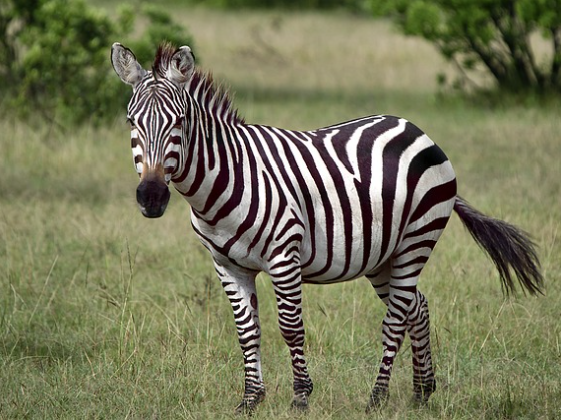

In [16]:
d=Image.open('/content/zebra.png')
d

In [18]:
import numpy as np
d1 = np.array(d)
d1

array([[[ 73,  82,  42, 255],
        [ 77,  87,  46, 255],
        [ 77,  88,  46, 255],
        ...,
        [ 31,  48,   8, 255],
        [ 35,  53,  10, 255],
        [ 43,  63,  16, 255]],

       [[ 74,  83,  45, 255],
        [ 77,  87,  47, 255],
        [ 77,  87,  46, 255],
        ...,
        [ 27,  44,   5, 255],
        [ 30,  48,   6, 255],
        [ 38,  57,  12, 255]],

       [[ 82,  90,  53, 255],
        [ 84,  93,  55, 255],
        [ 81,  91,  51, 255],
        ...,
        [ 28,  44,   6, 255],
        [ 30,  47,   6, 255],
        [ 35,  53,   9, 255]],

       ...,

       [[128, 132,  93, 255],
        [143, 139, 103, 255],
        [ 89,  86,  50, 255],
        ...,
        [138, 143, 109, 255],
        [ 80,  85,  50, 255],
        [ 84,  90,  54, 255]],

       [[116, 120,  81, 255],
        [151, 146, 110, 255],
        [125, 121,  85, 255],
        ...,
        [118, 123,  90, 255],
        [ 70,  76,  41, 255],
        [106, 112,  74, 255]],

       [[115

In [19]:
d1.shape

(420, 561, 4)

array([[ 69,  74,  74, ...,  34,  38,  47],
       [ 71,  74,  74, ...,  30,  33,  41],
       [ 78,  81,  78, ...,  31,  33,  38],
       ...,
       [120, 129,  76, ..., 132,  74,  79],
       [108, 136, 111, ..., 113,  65, 100],
       [107, 127, 117, ...,  90,  91,  83]], shape=(420, 561), dtype=uint8)
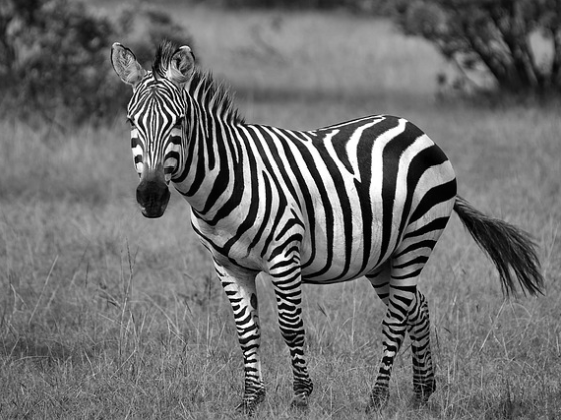

In [25]:
import cv2
dg = cv2.cvtColor(d1,cv2.COLOR_BGR2GRAY)
dg



array([[ 69,  74,  74, ...,  34,  38,  47],
       [ 71,  74,  74, ...,  30,  33,  41],
       [ 78,  81,  78, ...,  31,  33,  38],
       ...,
       [120, 129,  76, ..., 132,  74,  79],
       [108, 136, 111, ..., 113,  65, 100],
       [107, 127, 117, ...,  90,  91,  83]], shape=(420, 561), dtype=uint8)
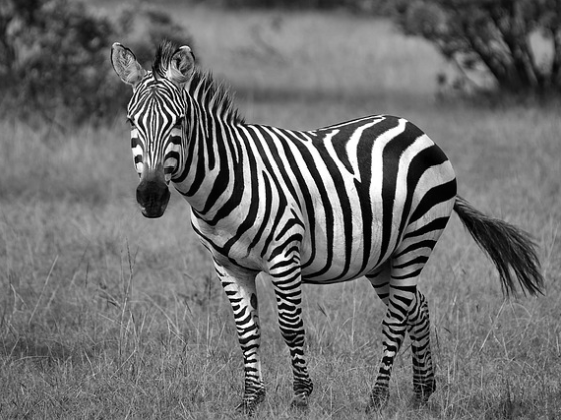

In [26]:
d2 = np.array(dg)
d2

In [28]:
d2.shape
img = cv2.resize(d2,(28,28))
img= img/255.0
img = img.reshape(1,28,28,1)
prediction = model.predict(img)
print(prediction)
digit = np.argmax(prediction)
digit


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step
[[0.15678273 0.00761292 0.15750147 0.12069434 0.00116388 0.05614679
  0.02854592 0.0134896  0.4176371  0.04042524]]


np.int64(8)

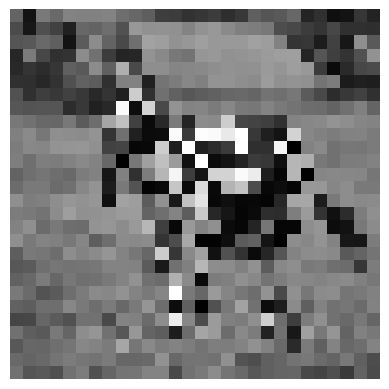

In [30]:
import matplotlib.pyplot as plt
plt.imshow(img[0,:,:,0],cmap = 'gray')
plt.axis('off')
plt.show()
